
# SQL Data Warehousing Project: Analyzing the 2008 Financial Crisis
Walkthrough/Template/Data: https://colab.research.google.com/drive/<redacted-course-data-file>?usp=sharing

## Project Objectives
1. Build an efficient SQL database to analyze the Global Financial Crisis using Barra data
2. Demonstrate mastery of SQL data warehousing concepts:
   - Proper schema design with multiple tables
   - Data type optimization and NULL handling
   - Primary keys and composite indices
   - Complex SQL queries using CTEs, Views, and Subqueries
   - JOIN operations (INNER, LEFT, and simulated FULL OUTER)
   - Transaction management with ROLLBACK/COMMIT

## Important Data Considerations

### Column Naming Best Practices
The Barra dataset includes columns with '%' in their names (e.g., 'SRISK%', 'TRISK%', 'WGT1%'). Consider:
- Is this best practice for database column naming?
- How should you handle these in your schema?
- Document your approach and any renaming decisions

### Estimation Universe Filter
- Use stocks in the 2007 estimation universe: `E3ESTU = 1` or `NONESTU = 0`
- These represent investible stocks in 2007
- When calculating percent changes to 2008, include all stocks to avoid survivorship bias
- Document how you handle companies that become uninvestible

## Required Technical Demonstrations

### 1. Database Schema Design (20%)
* Create at least 3 tables:
  - 2007 Barra USE3 data
  - 2008 Barra USE3 data  
  - Industry-to-Sector mapping (from PDF pages 83-84)
* Use the Industry-to-Sector table for all sector-related queries
* Address column naming issues (columns with '%')
* Optimize data types with justification
* Implement primary keys and foreign key relationships
* Create both single and composite indices

### 2. Risk Metrics Analysis (25%)
**Key Decisions Required:**

**Beta Comparison:**
- Compare 'HBTA' vs 'BETA' columns
- Research differences in the Barra handbook
- Recommend which the risk management division should use with justification

**Risk Measure Comparison:**
- Compare 'SRISK%' vs 'TRISK%'
- Research differences in the Barra handbook
- Recommend which measure for risk assessment with justification

**Risk Prediction Model:**
Using SQL, calculate mean and standard deviation for potential risk indicators:
- TRADEACT (trading activity)
- VOLTILTY (volatility)
- MOMENTUM
- VALUE
- EARNVAR (earnings variability)
- LEVERAGE

Determine which factors (individually or in combination) best predict PCT_CHANGE between 2007-2008.

### 3. Transaction Management (15%)
**Scenario**: Your risk management department has a "crystal ball" predicting the 2008 crisis.

Demonstrate a transaction that:
* Identifies Bear Stearns and Lehman Brothers BARRIDs
* Temporarily adjusts their risk metrics based on "prediction"
* Analyzes impact on portfolio risk
* Uses ROLLBACK to restore original data
* Documents the what-if analysis results

### **4. Sector Analysis (20%)**
Financial Services Deep Dive:
- Use your Industry-to-Sector mapping table to query which industries belong to the Financial Services sector
- Use the resulting industry list in your WHERE clause with INDNAME1
- Analyze sector-specific risk patterns
- Compare Financial Services sector performance against other sectors

### 5. Complex Query Techniques (20%)
Implement the same analysis using all three methods:
* **CTE (WITH clause)**: For multi-step calculations
* **VIEW**: For reusable logic
* **SUBQUERY**: For inline calculations

Compare performance and readability, recommend the best approach.

Example of query to identify risky companies to a hypothetical risk committee:
- Calculate z-scores for multiple risk factors
- Identify outliers within each sector (by cross referencing INDNAME1 with the Industry-to-Sector table).
- Rank companies by composite risk score

### 6. JOIN Operations Showcase (20%)
Demonstrate these JOIN types with meaningful analysis:
* **INNER JOIN**: Companies surviving both years
* **LEFT JOIN**: All 2007 companies, showing which disappeared
* **Simulated FULL OUTER JOIN**: Complete picture using UNION approach
* Show proper NULL handling in JOIN results

## Analysis Requirements

### Core Analyses (Complete ALL)

1. **Risk Factor Effectiveness**
   - Calculate statistics directly in SQL (mean, stddev)
   - Test each risk factor's predictive power
   - Identify optimal combination of factors
   - Use window functions for percentile rankings

2. **Survivor Analysis**
   - Track companies from 2007 to 2008
   - Avoid survivorship bias in calculations
   - Identify characteristics of survivors vs failures

3. **Sector Impact Study**
  - Complete the industry-to-sector mapping table from the Barra handbook
  - Query your mapping table to identify all industries in each sector
  - Use SQL JOINs between your mapping table and Barra data tables
  - Example query structure:
    - First: `SELECT INDNAME FROM ind_to_sectors WHERE SECTOR = 'Financials'`
    - Then use result in: `WHERE INDNAME1 IN (subquery or join result)`

4. **Beta and Risk Comparison**
   - Statistical comparison of HBTA vs BETA
   - Statistical comparison of SRISK% vs TRISK%
   - Recommendation with evidence

## Deliverables

### 1. Code Notebook
* Schema creation with column naming decisions
* Index creation and EXPLAIN plan analysis
* Transaction examples with Bear Stearns/Lehman scenarios
* All three query methods comparison
* Risk factor statistical calculations in SQL
* JOIN demonstrations with NULL handling

### 2. Database Documentation
* ERD showing all tables and relationships
* Column naming convention and any modifications
* Data type justifications
* Handling of estimation universe filtering
* NULL handling strategy

### 3. Analysis Report
* Executive summary of risk factor findings
* Beta and risk measure recommendations
* Sector impact analysis
* Visualizations (using Python after SQL retrieval)
* Performance metrics for different query approaches

### 4. Presentation Video (10-15 minutes)
* Live demonstration of:
  - Transaction with Bear Stearns/Lehman scenario
  - Risk factor statistical calculations
  - JOIN operations showing survivor analysis
  - Query method comparison (CTE vs View vs Subquery)
* Key insights about predictive risk factors
* Technical decisions and trade-offs

### 5. Trello Board
* Task assignments and progress
* Query development tracking
* Testing and optimization notes

## Grading Rubric

| Component | Weight | Details |
|-----------|--------|---------|
| Schema Design | 20% | Column naming, data types, keys, indices |
| Risk Analysis | 25% | Beta/risk comparison, factor effectiveness |
| SQL Techniques | 20% | CTEs, Views, Subqueries, JOINs |
| Transaction Management | 15% | Meaningful what-if scenarios |
| Sector Analysis | 15% | Complete mapping, financial services focus |
| Documentation | 5% | Clear, complete, professional |

## Key Requirements and Hints
* Build the complete industry-to-sector mapping table from Barra handbook PDF pages 83-84
  * Use SQL JOINs with your mapping table rather than hard-coding industry lists
  * All sector analysis should query the mapping table first, then join with Barra data
  * This demonstrates proper database normalization and JOIN usage
* Calculate all statistics (mean, stddev) directly in SQL, not Python
* Handle estimation universe filtering properly to avoid bias
* Performance matters - use EXPLAIN to show optimization
* Your risk predictions should be data-driven and justified
* Focus on SQL mastery, not financial theory

## Bonus Opportunities (up to 10% extra)
* Implement composite risk score using multiple factors
* Create automated column renaming system for best practices
* Build cross-validation framework in SQL
* Develop early warning system based on your findings
* Create interactive risk dashboard with parameterized queries

Remember: This project tests your SQL and data warehousing skills. Use the financial crisis as a compelling context to demonstrate sophisticated database techniques and analytical thinking.

# Barra Data from Dec 2007
* Before the Global Financial Crisis of 2008

In [ ]:
! gdown <redacted-course-data-file>

In [ ]:
! ls

In [ ]:
! head /content/USE3L0712.RSK

# Barra Data from Dec 2008
* After the Global Financial Crisis of 2008

In [ ]:
! gdown <redacted-course-data-file>

In [ ]:
! head USE3L0812.RSK

# EDA (Samantha)

---



In [ ]:
! head USE3L0812.RSK

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df_2007 = pd.read_csv('/content/USE3L0712.RSK', skiprows=1)
df_2008 = pd.read_csv('/content/USE3L0812.RSK', skiprows=1)

In [ ]:
df_2007

In [ ]:
df_2008

In [ ]:
df_2007.head()

In [ ]:
print("2007: ", df_2007.shape)
print("2008: ", df_2008.shape)

In [ ]:
print(df_2007.columns)

In [ ]:
print(df_2007.info())

In [ ]:
print(df_2008.info())

In [ ]:
df_2007.describe()

In [ ]:
df_2007.describe(include=['object', 'bool'])

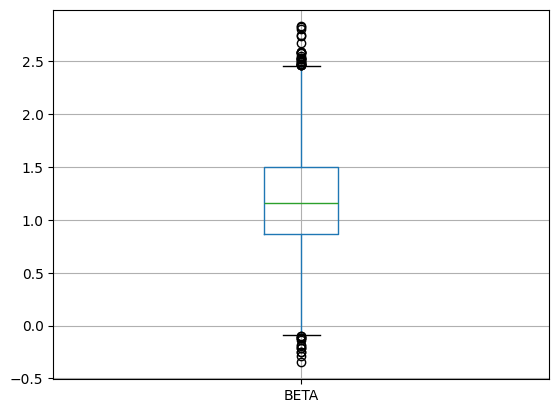

In [ ]:
df_2007[['BETA',]].boxplot()

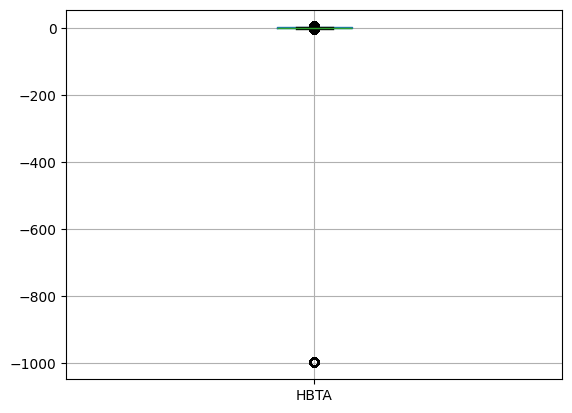

In [ ]:
df_2007[['HBTA',]].boxplot()

In [ ]:
df_2007.HBTA.min()

As you can see the HBTA data is abnormal, it shouldn't have any scores that low. Showing that the -999 is a nan placeholder. Let's remove the -999 placeholder values

In [ ]:
df_2007 = df_2007.replace(-999, np.nan)
df_2008 = df_2008.replace(-999, np.nan)

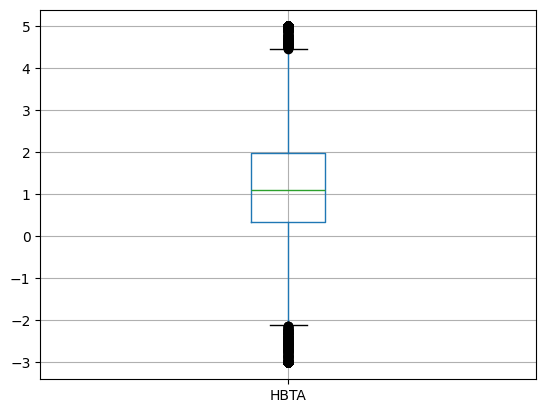

In [ ]:
df_2007[['HBTA',]].boxplot()

In [ ]:
df_2008.columns
df_2007.columns


In [ ]:
df_2007.columns = df_2007.columns.str.replace('%', '_PERCENT')
df_2008.columns = df_2008.columns.str.replace('%', '_PERCENT')
#replaces all the % signs with _PERCENT

In [ ]:
df_2007.columns = df_2007.columns.str.replace(' ', '')
df_2008.columns = df_2008.columns.str.replace(' ', '')
#replaces all the " " with ""(removes the empty spaces)

In [ ]:
df_2007.columns

In [ ]:
df_2008.columns

In [ ]:
print(repr(df_2007['INDNAME1']))

In [ ]:
print(repr(df_2007['INDNAME1'][0]))

In [ ]:
for col in df_2007.select_dtypes(include='object'):
    df_2007[col] = df_2007[col].str.strip()
for col in df_2008.select_dtypes(include='object'):
    df_2008[col] = df_2008[col].str.strip()

In [ ]:
print(repr(df_2007['INDNAME1'][0]))

This shows that the empty spaces after the element name are now gone

# Creating the SQL database (Samantha)

In [ ]:
import sqlalchemy
from sqlalchemy import create_engine, text

engine = create_engine('sqlite:///2008_crash.db')

In [ ]:
print(df_2007.dtypes.sort_values())
#sorts by the data type

In [ ]:
df_2007.dtypes.value_counts()

In [ ]:
print((sorted(df_2007['INDNAME1'].unique())))
#to make sure when I take from page 83 and 84 I use the right wrods

In [ ]:
#PAGE 83 AND 84 OF THE HANDBOOK using the .unique names

ind1sector = {
'BANKS': 'FINANCIAL',
'THRIFTS': 'FINANCIAL',
'SECASSET': 'FINANCIAL',
'FINSVCS': 'FINANCIAL',
'LIFEINS': 'FINANCIAL',
'PRPTYINS': 'FINANCIAL',

'INFOSVCS': 'COMMERCIAL_SERVICES',
'INDSVCS': 'COMMERCIAL_SERVICES',

'TELEPHON': 'TELECOMMUNICATIONS',
'WIRELESS': 'TELECOMMUNICATIONS',

'MEDPROVR': 'HEALTH_CARE',
'DRUGS': 'HEALTH_CARE',
'MEDPRODS': 'HEALTH_CARE',

'RAILROAD': 'TRANSPORT',
'AIRLINES': 'TRANSPORT',
'TRUCKFRT': 'TRANSPORT',

'SEMICOND': 'TECHNOLOGY',
'INTERNET': 'TECHNOLOGY',
'CMPTRHW': 'TECHNOLOGY',
'CMPTRSW': 'TECHNOLOGY',
'ELECEQP': 'TECHNOLOGY',
'DEFAERO': 'TECHNOLOGY',


'ELECUTIL': 'UTILITY',
'GASUTIL': 'UTILITY',


'HOMEPROD': 'CONSUMER_NONCYCLICALS',
'FOODBEV': 'CONSUMER_NONCYCLICALS',
'ALCOHOL': 'CONSUMER_NONCYCLICALS',
'TOBACCO': 'CONSUMER_NONCYCLICALS',
'GROCERY': 'CONSUMER_NONCYCLICALS',

'CONSDUR': 'CONSUMER_CYCLICALS',
'MOTORVEH': 'CONSUMER_CYCLICALS',
'APPAREL': 'CONSUMER_CYCLICALS',
'CLOTHING': 'CONSUMER_CYCLICALS',
'SPLTYRET': 'CONSUMER_CYCLICALS',
'DEPTSTOR': 'CONSUMER_CYCLICALS',
'CONSTRUC': 'CONSUMER_CYCLICALS',

'PUBLISH': 'CONSUMER_SERVICES',
'MEDIA': 'CONSUMER_SERVICES',
'HOTELS': 'CONSUMER_SERVICES',
'RESTRNTS': 'CONSUMER_SERVICES',
'ENTRTAIN': 'CONSUMER_SERVICES',
'LEISURE': 'CONSUMER_SERVICES',

'ENVSVCS': 'INDUSTRIALS',
'HEAVYELC': 'INDUSTRIALS',
'HEAVYMCH': 'INDUSTRIALS',
'INDPART': 'INDUSTRIALS',

'MINING': 'BASIC_MATERIALS',
'GOLD': 'BASIC_MATERIALS',
'FOREST': 'BASIC_MATERIALS',
'CHEMICAL': 'BASIC_MATERIALS',

'ENGYRES': 'ENERGY',
'OILREF': 'ENERGY',
'OILSVCS': 'ENERGY',

'BIOTECH': 'HEALTH_CARE',

'EQTYREIT': 'REAL_ESTATE',

}

In [ ]:
from sqlalchemy.types import Float, String, Integer
#object type will be string
data_types = {
    #9 string types
    'BARRID': String(50),
    'INDNAME5': String(100),
    'INDNAME4': String(100),
    'INDNAME3': String(100),
    'INDNAME2': String(100),
    'INDNAME1': String(100),
    'NAME': String(100),
    'CUSIP': String(50),
    'TICKER': String(50),

    #20 int types
    'E3ESTU': Integer,
    'WGT5_PERCENT': Integer,
    'WGT4_PERCENT': Integer,
    'WGT3_PERCENT': Integer,
    'WGT2_PERCENT': Integer,
    'WGT1_PERCENT': Integer,
    'IND5': Integer,
    'SAPVAL': Integer,
    'IND4': Integer,
    'SAPGRO': Integer,
    'IND3': Integer,
    'MIDCAP': Integer,
    'IND2': Integer,
    'SCGRO': Integer,
    'IND1': Integer,
    'MIDVAL': Integer,
    'SAP500': Integer,
    'SCVAL': Integer,
    'SC600': Integer,
    'MIDGRO': Integer,

    #20 float types
    'LEVERAGE': Float,
    'CAPITALIZATION': Float,
    'PRICE': Float,
    'HBTA': Float,
    'BETA': Float,
    'SRISK_PERCENT': Float,
    'TRISK_PERCENT': Float,
    'EARNVAR': Float,
    'VOLTILTY': Float,
    'SIZE': Float,
    'SIZENONL': Float,
    'TRADEACT': Float,
    'GROWTH': Float,
    'EARNYLD': Float,
    'VALUE': Float,
    'NONESTU': Float,
    'YLD_PERCENT': Float,
    'CURRSEN': Float,
    'MOMENTUM': Float,
    'YIELD': Float,
}

df_2007.to_sql('2007_data', con=engine, if_exists='replace', index=False, dtype=data_types)
df_2008.to_sql('2008_data', con=engine, if_exists='replace', index=False, dtype=data_types)


The object data type was turned into String since it contains text. The integer types were chosen because those columns have 0 or 1 values/ whole values and the risk metics with decimal values were turned to floats.

In [ ]:
#AI helped with these mapping lines
mapping_df = pd.DataFrame(list(ind1sector.items()), columns=['INDNAME', 'SECTOR'])
mapping_df.to_sql('ind_to_sectors', con=engine, if_exists='replace', index=False)
print(pd.read_sql("SELECT * FROM ind_to_sectors", engine))


In [ ]:
#AI assisted with text CREATE INDEX IF NOT EXISTS & helped me learn how .connection works
with engine.connect() as connection:
  #single
    connection.execute(text("CREATE INDEX IF NOT EXISTS idx_2007_data_barrid ON '2007_data' (BARRID)"))
    connection.execute(text("CREATE INDEX IF NOT EXISTS idx_2008_data_barrid ON '2008_data' (BARRID)"))
      #composite
    connection.execute(text("CREATE INDEX IF NOT EXISTS idx_2007_data_indname1 ON '2007_data' (INDNAME1, CAPITALIZATION)"))
    connection.execute(text("CREATE INDEX IF NOT EXISTS idx_2008_data_indname1 ON '2008_data' (INDNAME1, CAPITALIZATION)"))

    connection.commit()


Single indexes were created on BARRID as the primary identfier, since it's the unique idetifier that's used when you join the tables, and the compostite one was created on INDNAME1 and CAPITALIZATION since many queries filter by industry and market size

# Zeeshan (Risk Analysis)

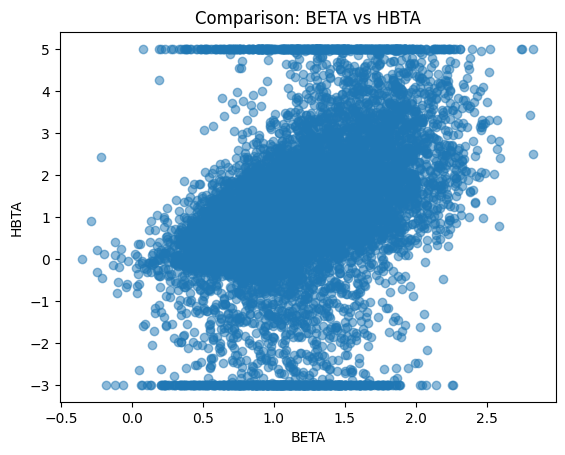

In [ ]:
import duckdb
import matplotlib.pyplot as plt

# Calculate HBTA vs BETA
hbta_df = df_2007[['BARRID', 'HBTA', 'BETA']].dropna()

# SQL query to calculate descriptive stats + correlation
query = """
SELECT
    COUNT(*) AS count,
    AVG(HBTA) AS mean_hbta,
    STDDEV_POP(HBTA) AS std_hbta,
    MIN(HBTA) AS min_hbta,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY HBTA) AS hbta_25,
    PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY HBTA) AS hbta_50,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY HBTA) AS hbta_75,
    MAX(HBTA) AS max_hbta,

    AVG(BETA) AS mean_beta,
    STDDEV_POP(BETA) AS std_beta,
    MIN(BETA) AS min_beta,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY BETA) AS beta_25,
    PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY BETA) AS beta_50,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY BETA) AS beta_75,
    MAX(BETA) AS max_beta,

    CORR(HBTA, BETA) AS correlation
FROM hbta_df
"""

df_sql = duckdb.query(query).to_df()
data = {
    'HBTA': [
        df_sql['count'][0],
        df_sql['mean_hbta'][0],
        df_sql['std_hbta'][0],
        df_sql['min_hbta'][0],
        df_sql['hbta_25'][0],
        df_sql['hbta_50'][0],
        df_sql['hbta_75'][0],
        df_sql['max_hbta'][0]
    ],
    'BETA': [
        df_sql['count'][0],
        df_sql['mean_beta'][0],
        df_sql['std_beta'][0],
        df_sql['min_beta'][0],
        df_sql['beta_25'][0],
        df_sql['beta_50'][0],
        df_sql['beta_75'][0],
        df_sql['max_beta'][0]
    ]
}

index = ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
df_stats = pd.DataFrame(data, index=index)

print("Descriptive Statistics for HBTA vs BETA:")
print(df_stats)
print(f"\nCorrelation between HBTA and BETA: {df_sql['correlation'][0]:.3f}")

# Scatter plot for visual view
df_scatter = duckdb.query("SELECT BETA, HBTA FROM hbta_df").to_df()
plt.scatter(df_scatter['BETA'], df_scatter['HBTA'], alpha=0.5)
plt.xlabel('BETA')
plt.ylabel('HBTA')
plt.title('Comparison: BETA vs HBTA')
plt.show()

In [ ]:

print(df_2007.columns)

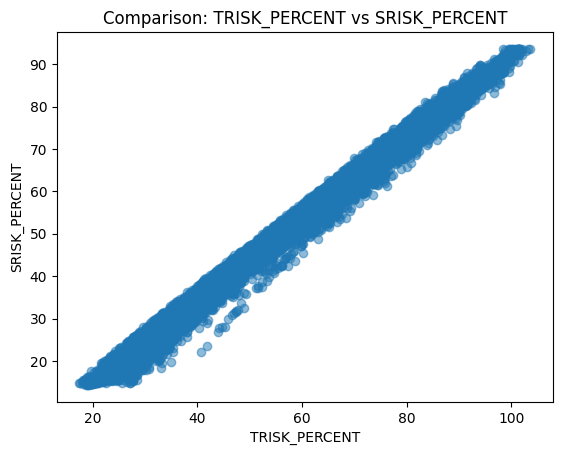

In [ ]:
# SRISK VS TRISK


risk_df = df_2007[['BARRID', 'SRISK_PERCENT', 'TRISK_PERCENT']].dropna()
query = """
SELECT
    COUNT(*) AS count,
    AVG(SRISK_PERCENT) AS mean_srisk,
    STDDEV_POP(SRISK_PERCENT) AS std_srisk,
    MIN(SRISK_PERCENT) AS min_srisk,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY SRISK_PERCENT) AS srisk_25,
    PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY SRISK_PERCENT) AS srisk_50,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY SRISK_PERCENT) AS srisk_75,
    MAX(SRISK_PERCENT) AS max_srisk,

    AVG(TRISK_PERCENT) AS mean_trisk,
    STDDEV_POP(TRISK_PERCENT) AS std_trisk,
    MIN(TRISK_PERCENT) AS min_trisk,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY TRISK_PERCENT) AS trisk_25,
    PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY TRISK_PERCENT) AS trisk_50,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY TRISK_PERCENT) AS trisk_75,
    MAX(TRISK_PERCENT) AS max_trisk,

    CORR(SRISK_PERCENT, TRISK_PERCENT) AS correlation
FROM risk_df
"""

df_sql = duckdb.query(query).to_df()

data = {
    'SRISK_PERCENT': [
        df_sql['count'][0],
        df_sql['mean_srisk'][0],
        df_sql['std_srisk'][0],
        df_sql['min_srisk'][0],
        df_sql['srisk_25'][0],
        df_sql['srisk_50'][0],
        df_sql['srisk_75'][0],
        df_sql['max_srisk'][0]
    ],
    'TRISK_PERCENT': [
        df_sql['count'][0],
        df_sql['mean_trisk'][0],
        df_sql['std_trisk'][0],
        df_sql['min_trisk'][0],
        df_sql['trisk_25'][0],
        df_sql['trisk_50'][0],
        df_sql['trisk_75'][0],
        df_sql['max_trisk'][0]
    ]
}

index = ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
df_stats = pd.DataFrame(data, index=index)

# Print formatted stats
print(df_stats)
print(f"\nCorrelation between SRISK_PERCENT and TRISK_PERCENT: {df_sql['correlation'][0]:.3f}")

# Scatter plot
df_scatter = duckdb.query("SELECT TRISK_PERCENT, SRISK_PERCENT FROM risk_df").to_df()
plt.scatter(df_scatter['TRISK_PERCENT'], df_scatter['SRISK_PERCENT'], alpha=0.5)
plt.xlabel('TRISK_PERCENT')
plt.ylabel('SRISK_PERCENT')
plt.title('Comparison: TRISK_PERCENT vs SRISK_PERCENT')
plt.show()

In [ ]:


# Select the relevant risk indicators
risk_factors = ['TRADEACT', 'VOLTILTY', 'MOMENTUM', 'VALUE', 'EARNVAR', 'LEVERAGE']
risk_df = df_2007[risk_factors].dropna()

#  Calculate mean and standard deviation
risk_stats = risk_df.agg(['mean', 'std'])
print("Mean and Standard Deviation for Risk Indicators:\n")
print(risk_stats)



In [ ]:
# Merge 2007 and 2008 price
df_prices = df_2007[['BARRID', 'PRICE']].merge(
    df_2008[['BARRID', 'PRICE']],
    on='BARRID',
    suffixes=('_2007', '_2008')
)

# Calculate % change
df_prices['PCT_CHANGE'] = (df_prices['PRICE_2008'] - df_prices['PRICE_2007']) / df_prices['PRICE_2007'] * 100

df_prices.head()

In [ ]:
# Select risk factors from 2007
risk_factors = ['TRADEACT', 'VOLTILTY', 'MOMENTUM', 'VALUE', 'EARNVAR', 'LEVERAGE']
df_model = df_2007[['BARRID'] + risk_factors].merge(df_prices[['BARRID', 'PCT_CHANGE']], on='BARRID')

df_model.head()

In [ ]:
# Check correlation between each factor and PCT_CHANGE
correlations = df_model[risk_factors + ['PCT_CHANGE']].corr()['PCT_CHANGE'].sort_values(ascending=False)
print("Correlation with PCT_CHANGE:")
print(correlations)

In [ ]:
# Used AI
import statsmodels.api as sm

X = df_model[risk_factors]
y = df_model['PCT_CHANGE']

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()

print(model.summary())

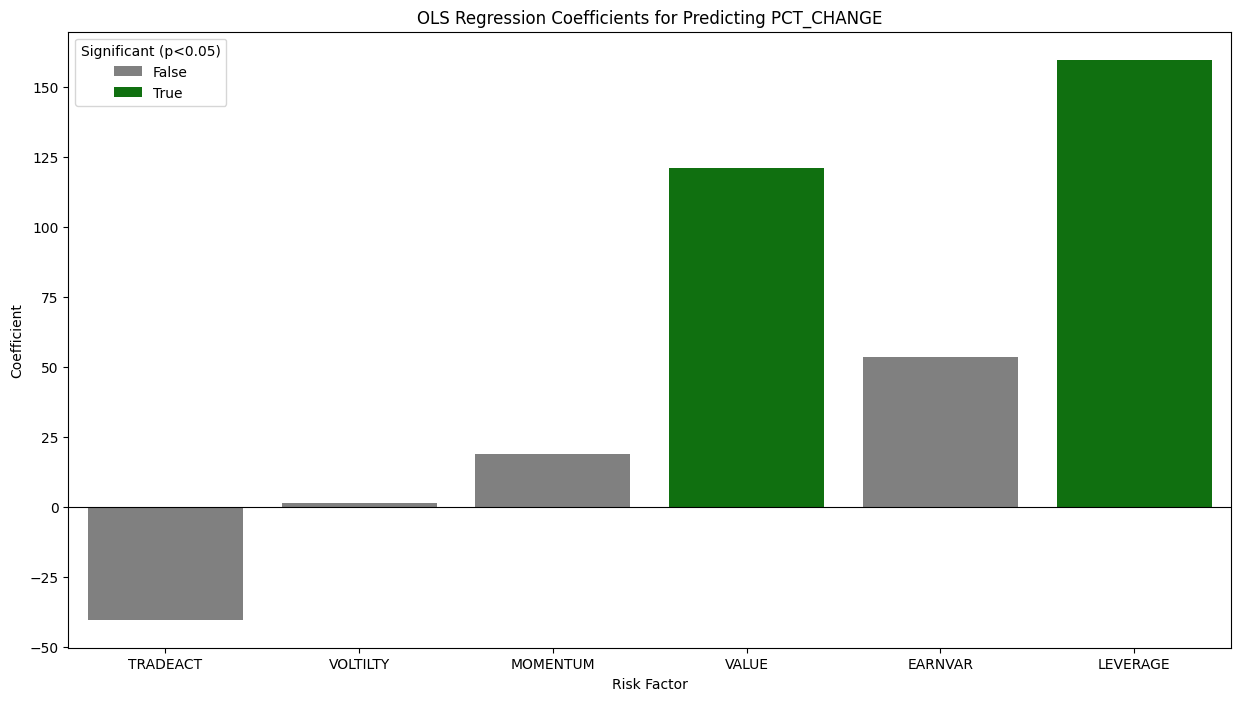

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Coefficients and p-values from your OLS model
coefficients = {
    'TRADEACT': -40.4261,
    'VOLTILTY': 1.2701,
    'MOMENTUM': 18.8852,
    'VALUE': 121.0886,
    'EARNVAR': 53.3366,
    'LEVERAGE': 159.7484
}

p_values = {
    'TRADEACT': 0.271,
    'VOLTILTY': 0.969,
    'MOMENTUM': 0.531,
    'VALUE': 0.000,
    'EARNVAR': 0.263,
    'LEVERAGE': 0.000
}

# Create dataframe for plotting
coef_df = pd.DataFrame({
    'Factor': list(coefficients.keys()),
    'Coefficient': list(coefficients.values()),
    'p_value': list(p_values.values())
})

# Mark significance
coef_df['Significant'] = coef_df['p_value'] < 0.05

# Plot
plt.figure(figsize=(15,8))
sns.barplot(data=coef_df, x='Factor', y='Coefficient', hue='Significant', dodge=False, palette={True:'green', False:'gray'})
plt.title('OLS Regression Coefficients for Predicting PCT_CHANGE')
plt.ylabel('Coefficient')
plt.xlabel('Risk Factor')
plt.legend(title='Significant (p<0.05)')
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

# Transcation Management (Alexander)

In [ ]:
from sqlalchemy import text

# confirm bear stearns and lehman are in the dataset
with engine.connect() as conn:
    check = conn.execute(text("""
        SELECT BARRID, NAME, INDNAME1
        FROM `2007_data`
        WHERE NAME LIKE '%Bear%'
           OR NAME LIKE '%Lehman%'
    """)).fetchall()
    print("BARRID verification:")
    for row in check:
        print(row)

In [ ]:
from sqlalchemy import text

targets = ('USABM91', 'USARHS2')

with engine.connect() as conn:
    trans = conn.begin()
    try:
        # grab original values before changing anything
        orig = conn.execute(text(
            f"SELECT NAME, LEVERAGE, SRISK_PERCENT FROM `2007_data` WHERE BARRID IN {targets}"
        )).fetchall()
        print("Before Spike")
        for row in orig:
            print(row)

        # baseline financial sector avg
        before = conn.execute(text("""
            SELECT AVG(d.SRISK_PERCENT)
            FROM `2007_data` d
            JOIN ind_to_sectors m ON d.INDNAME1 = m.INDNAME
            WHERE m.SECTOR = 'FINANCIAL'
        """)).fetchone()
        print(f"\nFinancial Sector Avg Risk (before): {before[0]:.2f}%")

        # spike both companies to simulate crisis exposure
        conn.execute(text(
            f"UPDATE `2007_data` SET LEVERAGE = 99.9, SRISK_PERCENT = 99.9 WHERE BARRID IN {targets}"
        ))

        # check sector avg after spike
        after = conn.execute(text("""
            SELECT AVG(d.SRISK_PERCENT)
            FROM `2007_data` d
            JOIN ind_to_sectors m ON d.INDNAME1 = m.INDNAME
            WHERE m.SECTOR = 'FINANCIAL'
        """)).fetchone()
        print(f"Financial Sector Avg Risk (after):  {after[0]:.2f}%")

        change = after[0] - before[0]
        print(f"Impact: +{change:.2f} pp ({(change / before[0]) * 100:.1f}% increase)")

        # rollback so we dont mess up the data
        trans.rollback()
        print("ROLLBACK done")

        # confirm original values are back
        restored = conn.execute(text(
            f"SELECT NAME, LEVERAGE, SRISK_PERCENT FROM `2007_data` WHERE BARRID IN {targets}"
        )).fetchall()
        print("After Rollback")
        for row in restored:
            print(row)

    except Exception as e:
        trans.rollback()
        print(f"Error: {e}")

# Sector Analysis (Alexander)

In [ ]:
# Lets look at the top 10 riskiest financial companies in the investible universe
fin_query = text("""
SELECT
    NAME,
    TICKER,
    INDNAME1,
    ROUND(LEVERAGE, 2) AS LEVERAGE,
    ROUND(SRISK_PERCENT, 2) AS SRISK_PERCENT
FROM `2007_data`
WHERE (E3ESTU = 1 OR NONESTU = 0)
  AND INDNAME1 IN (
      SELECT INDNAME FROM ind_to_sectors WHERE SECTOR = 'FINANCIAL'
  )
ORDER BY SRISK_PERCENT DESC
LIMIT 10;
""")

# compare all sectors by leverage, risk and 2008 performance
# left join keeps companies that disappeared in 2008
sector_query = text("""
SELECT
    m.SECTOR,
    COUNT(d07.BARRID) AS Company_Count,
    ROUND(AVG(d07.LEVERAGE), 2) AS Avg_Leverage_2007,
    ROUND(AVG(d07.SRISK_PERCENT), 2) AS Avg_Systemic_Risk_2007,
    ROUND(AVG((d08.PRICE - d07.PRICE) / NULLIF(d07.PRICE, 0) * 100), 2) AS Avg_Performance_2008
FROM ind_to_sectors m
JOIN `2007_data` d07
    ON m.INDNAME = d07.INDNAME1
    AND (d07.E3ESTU = 1 OR d07.NONESTU = 0)
LEFT JOIN `2008_data` d08 ON d07.BARRID = d08.BARRID
GROUP BY m.SECTOR
ORDER BY Avg_Performance_2008 ASC;
""")

with engine.connect() as conn:
    fin_df = pd.read_sql(fin_query, conn)
    sector_df = pd.read_sql(sector_query, conn)

print("Top 10 Riskiest Financial Companies (Dec 2007)")
print(fin_df.to_string(index=False))
print("Sector Risk vs 2008 Performance")
print(sector_df.to_string(index=False))

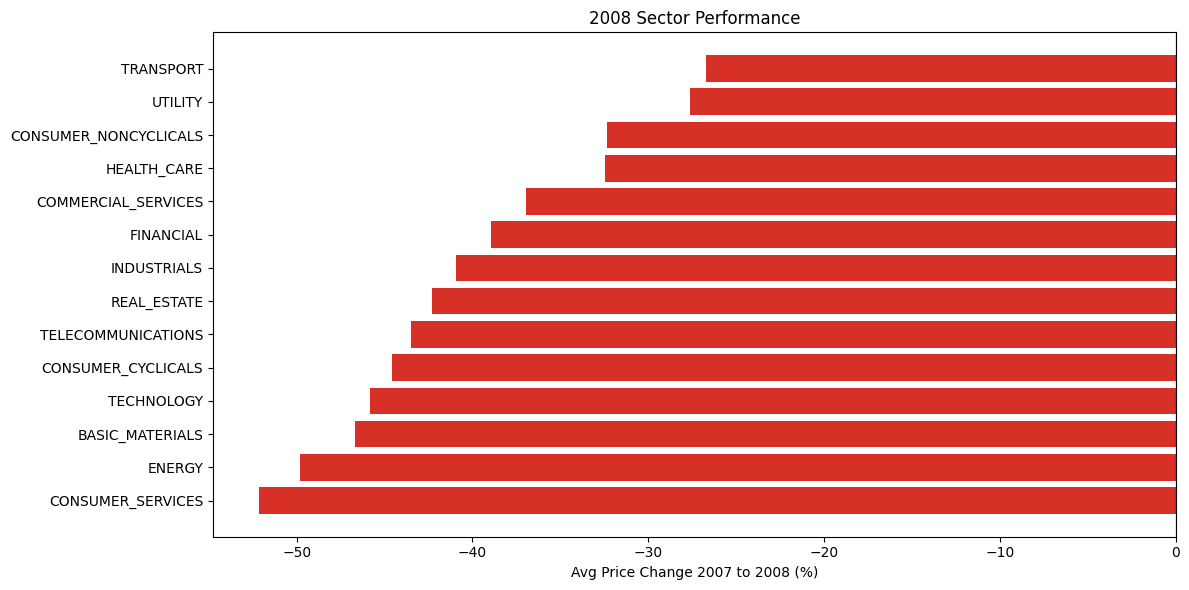

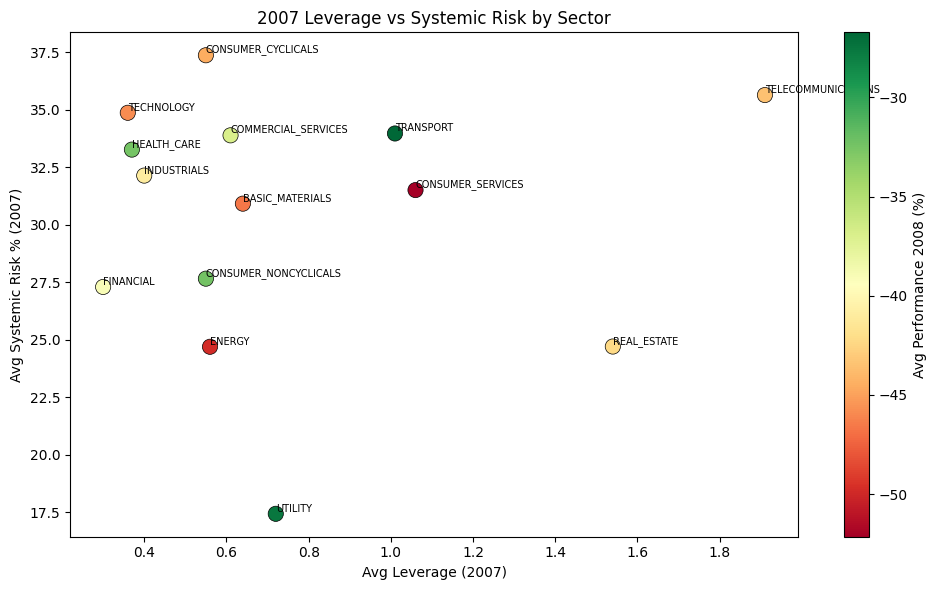

In [ ]:
# bar chart of 2008 performance by sector
plot_df = sector_df.dropna(subset=['Avg_Performance_2008']).sort_values('Avg_Performance_2008')
colors = ['#d73027' if x < -20 else '#fc8d59' if x < 0 else '#91cf60'
          for x in plot_df['Avg_Performance_2008']]

plt.figure(figsize=(12, 6))
plt.barh(plot_df['SECTOR'], plot_df['Avg_Performance_2008'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Avg Price Change 2007 to 2008 (%)')
plt.title('2008 Sector Performance')
plt.tight_layout()
plt.show()

# scatter plot of leverage vs systemic risk, colored by 2008 performance
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    sector_df['Avg_Leverage_2007'],
    sector_df['Avg_Systemic_Risk_2007'],
    c=sector_df['Avg_Performance_2008'],
    cmap='RdYlGn', s=120, edgecolors='black', linewidths=0.5
)
plt.colorbar(scatter, label='Avg Performance 2008 (%)')
for _, row in sector_df.iterrows():
    if pd.notna(row['Avg_Leverage_2007']) and pd.notna(row['Avg_Systemic_Risk_2007']):
        plt.annotate(row['SECTOR'], (row['Avg_Leverage_2007'], row['Avg_Systemic_Risk_2007']),
                     fontsize=7, ha='left', va='bottom')
plt.xlabel('Avg Leverage (2007)')
plt.ylabel('Avg Systemic Risk % (2007)')
plt.title('2007 Leverage vs Systemic Risk by Sector')
plt.tight_layout()
plt.show()

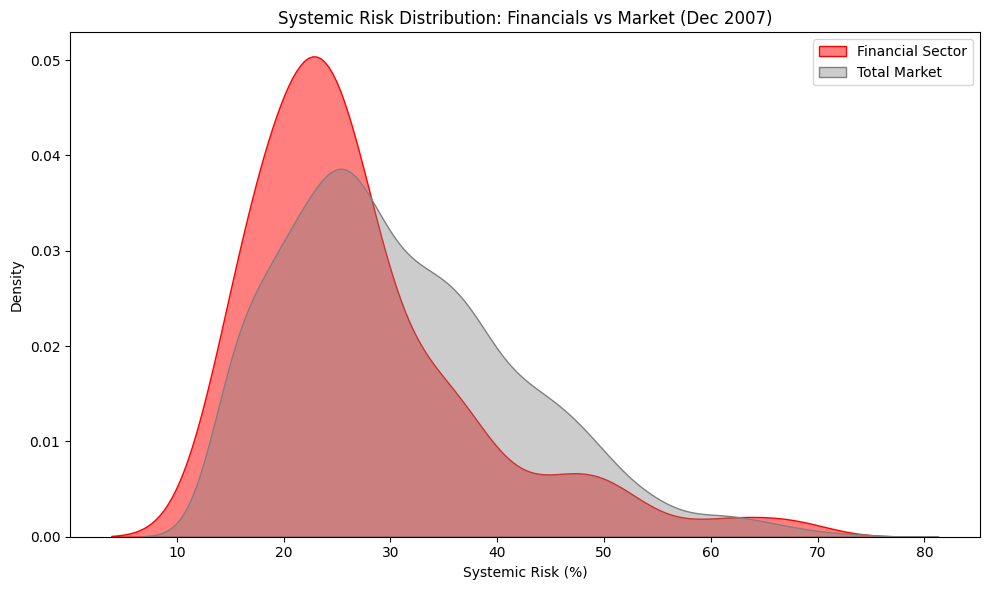

In [ ]:
# pull financial industry list from mapping table
with engine.connect() as conn:
    fin_industries = pd.read_sql(
        text("SELECT INDNAME FROM ind_to_sectors WHERE SECTOR = 'FINANCIAL'"), conn
    )['INDNAME'].tolist()

# filter to investible universe
investible_mask = (df_2007['E3ESTU'] == 1) | (df_2007['NONESTU'] == 0)
kde_df = df_2007[investible_mask].copy()
fin_mask = kde_df['INDNAME1'].isin(fin_industries)

# kde plot comparing financial sector vs total market
plt.figure(figsize=(10, 6))
sns.kdeplot(kde_df[fin_mask]['SRISK_PERCENT'].dropna(),
            label='Financial Sector', fill=True, color='red', alpha=0.5)
sns.kdeplot(kde_df['SRISK_PERCENT'].dropna(),
            label='Total Market', fill=True, color='gray', alpha=0.4)
plt.title('Systemic Risk Distribution: Financials vs Market (Dec 2007)')
plt.xlabel('Systemic Risk (%)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Financial Sector Mean: {kde_df[fin_mask]['SRISK_PERCENT'].mean():.2f}% | Median: {kde_df[fin_mask]['SRISK_PERCENT'].median():.2f}%")
print(f"Total Market     Mean: {kde_df['SRISK_PERCENT'].mean():.2f}% | Median: {kde_df['SRISK_PERCENT'].median():.2f}%")

#Financial Sector Analysis

After looking at the top 10 riskiest financial companies in December 2007, the results are not what you would expect. The list is not the big investment banks most people associate with the crisis; it is mostly financial services and insurance companies directly exposed to subprime mortgages and consumer credit. CompuCredit led at 66.84%, followed by IndyMac at 61.49% and Countrywide at 51.70%. Bear Stearns and Lehman do not even appear here, their systemic risk of around 29% was elevated but not extreme. The firms the Barra model flagged as most dangerous were the ones tied most directly to mortgage origination, consumer lending, and mortgage insurance.



# Sector Comparison
Every sector lost money in 2008 but Financial was not the worst performer. Consumer Services dropped 52.15%, Energy 49.81%, and Basic Materials 46.68%. Financial came in 9th out of 14 at 38.95% down with the lowest average leverage of any sector at 0.30. That result is partly explained by survivorship bias collapsed firms like Bear Stearns and Lehman have no December 2008 price in the Barra file so they get excluded from the average, making Financial look better than it actually was (this would be Survivorship bias). Utilities, Health Care, and Consumer Noncyclicals held up best because demand for those products stays relatively stable regardless of economic conditions.

# Risk Distribution
The KDE plot is a smoothed histogram showing where companies cluster in terms of systemic risk. The Financial sector curve peaks to the left of the total market around 22-23%, meaning most financial firms were at moderate or below average risk heading into 2008. The important feature is the small right tail firms like IndyMac, CompuCredit, and Countrywide sitting above 60%. They were a minority within their own sector but the ones that caused the most damage, and the model had already flagged them as outliers in December 2007.

# 5. Complex Query Techniques (20%)  - Talha
Implement the same analysis using all three methods:

CTE (WITH clause): For multi-step calculations
VIEW: For reusable logic
SUBQUERY: For inline calculations
Compare performance and readability, recommend the best approach.

Example of query to identify risky companies to a hypothetical risk committee:

Calculate z-scores for multiple risk factors
Identify outliers within each sector (by cross referencing INDNAME1 with the Industry-to-Sector table).
Rank companies by composite risk score


In [ ]:
# Step 1: create indices to speed joins/filters
from sqlalchemy import text

with engine.connect() as conn:
    conn.execute(text("CREATE INDEX IF NOT EXISTS idx_2007_barrid ON '2007_data'(BARRID)"))
    conn.execute(text("CREATE INDEX IF NOT EXISTS idx_2008_barrid ON '2008_data'(BARRID)"))
    conn.execute(text("CREATE INDEX IF NOT EXISTS idx_2007_indname1 ON '2007_data'(INDNAME1)"))
    conn.execute(text("CREATE INDEX IF NOT EXISTS idx_ind_to_sectors_indname ON ind_to_sectors(INDNAME)"))
    conn.commit()
    print('Indexes created/ensured: idx_2007_barrid, idx_2008_barrid, idx_2007_indname1, idx_ind_to_sectors_indname')

In [ ]:
# Step 2: compute percent price change from 2007 to 2008 (store as table pct_changes)
from sqlalchemy import text

sql = """
DROP TABLE IF EXISTS pct_changes;
CREATE TABLE pct_changes AS
SELECT
  d07.BARRID,
  d07.PRICE AS PRICE_2007,
  d08.PRICE AS PRICE_2008,
  CASE
    WHEN d07.PRICE IS NULL OR d07.PRICE = 0 THEN NULL
    ELSE (d08.PRICE - d07.PRICE) / d07.PRICE * 100.0
  END AS PCT_CHANGE
FROM "2007_data" d07
LEFT JOIN "2008_data" d08 ON d07.BARRID = d08.BARRID;
"""
with engine.connect() as conn:
    # sqlite3 engine via SQLAlchemy executes one statement at a time; split
    for stmt in sql.strip().split(';'):
        if stmt.strip():
            conn.execute(text(stmt))
    conn.commit()
    print("pct_changes table created with PCT_CHANGE (2007 -> 2008).")

In [ ]:
# Step 3: create view for composite z-scores by sector
from sqlalchemy import text

create_view_sql = """
DROP VIEW IF EXISTS vw_sector_composite_risk;
CREATE VIEW vw_sector_composite_risk AS
WITH base AS (
  SELECT d.BARRID, d.NAME, d.TICKER, d.INDNAME1, m.SECTOR,
         d.TRADEACT, d.VOLTILTY, d.MOMENTUM, d.VALUE, d.EARNVAR, d.LEVERAGE
  FROM "2007_data" d
  JOIN ind_to_sectors m ON d.INDNAME1 = m.INDNAME
  WHERE d.BARRID IS NOT NULL
),
sector_stats AS (
  SELECT
    SECTOR,
    COUNT(TRADEACT) AS n_tradeact,
    AVG(TRADEACT) AS mean_tradeact,
    (AVG(TRADEACT*TRADEACT) - AVG(TRADEACT)*AVG(TRADEACT)) AS var_pop_tradeact,

    COUNT(VOLTILTY) AS n_vol,
    AVG(VOLTILTY) AS mean_vol,
    (AVG(VOLTILTY*VOLTILTY) - AVG(VOLTILTY)*AVG(VOLTILTY)) AS var_pop_vol,

    COUNT(MOMENTUM) AS n_mom,
    AVG(MOMENTUM) AS mean_mom,
    (AVG(MOMENTUM*MOMENTUM) - AVG(MOMENTUM)*AVG(MOMENTUM)) AS var_pop_mom,

    COUNT(VALUE) AS n_val,
    AVG(VALUE) AS mean_val,
    (AVG(VALUE*VALUE) - AVG(VALUE)*AVG(VALUE)) AS var_pop_val,

    COUNT(EARNVAR) AS n_earn,
    AVG(EARNVAR) AS mean_earn,
    (AVG(EARNVAR*EARNVAR) - AVG(EARNVAR)*AVG(EARNVAR)) AS var_pop_earn,

    COUNT(LEVERAGE) AS n_lev,
    AVG(LEVERAGE) AS mean_lev,
    (AVG(LEVERAGE*LEVERAGE) - AVG(LEVERAGE)*AVG(LEVERAGE)) AS var_pop_lev

  FROM base
  GROUP BY SECTOR
),
sector_stats_corrected AS (
  SELECT
    SECTOR,
    mean_tradeact,
    CASE WHEN n_tradeact > 1 THEN SQRT(var_pop_tradeact * (n_tradeact/(n_tradeact-1.0))) ELSE NULL END AS sd_tradeact,
    mean_vol,
    CASE WHEN n_vol > 1 THEN SQRT(var_pop_vol * (n_vol/(n_vol-1.0))) ELSE NULL END AS sd_vol,
    mean_mom,
    CASE WHEN n_mom > 1 THEN SQRT(var_pop_mom * (n_mom/(n_mom-1.0))) ELSE NULL END AS sd_mom,
    mean_val,
    CASE WHEN n_val > 1 THEN SQRT(var_pop_val * (n_val/(n_val-1.0))) ELSE NULL END AS sd_val,
    mean_earn,
    CASE WHEN n_earn > 1 THEN SQRT(var_pop_earn * (n_earn/(n_earn-1.0))) ELSE NULL END AS sd_earn,
    mean_lev,
    CASE WHEN n_lev > 1 THEN SQRT(var_pop_lev * (n_lev/(n_lev-1.0))) ELSE NULL END AS sd_lev
  FROM sector_stats
)
SELECT
  b.BARRID, b.NAME, b.TICKER, b.INDNAME1, b.SECTOR,
  b.TRADEACT, b.VOLTILTY, b.MOMENTUM, b.VALUE, b.EARNVAR, b.LEVERAGE,

  (b.TRADEACT - s.mean_tradeact) / NULLIF(s.sd_tradeact, 0) AS z_tradeact,
  (b.VOLTILTY  - s.mean_vol)       / NULLIF(s.sd_vol, 0)       AS z_vol,
  (b.MOMENTUM  - s.mean_mom)       / NULLIF(s.sd_mom, 0)       AS z_mom,
  (b.VALUE     - s.mean_val)       / NULLIF(s.sd_val, 0)       AS z_val,
  (b.EARNVAR   - s.mean_earn)      / NULLIF(s.sd_earn, 0)      AS z_earn,
  (b.LEVERAGE  - s.mean_lev)       / NULLIF(s.sd_lev, 0)       AS z_lev,

  (
    0.15 * COALESCE((b.TRADEACT - s.mean_tradeact) / NULLIF(s.sd_tradeact,0),0) +
    0.20 * COALESCE((b.VOLTILTY  - s.mean_vol)       / NULLIF(s.sd_vol,0),0) +
    0.15 * COALESCE((b.MOMENTUM  - s.mean_mom)       / NULLIF(s.sd_mom,0),0) +
    0.15 * COALESCE((b.VALUE     - s.mean_val)       / NULLIF(s.sd_val,0),0) +
    0.20 * COALESCE((b.EARNVAR   - s.mean_earn)      / NULLIF(s.sd_earn,0),0) +
    0.15 * COALESCE((b.LEVERAGE  - s.mean_lev)       / NULLIF(s.sd_lev,0),0)
  ) AS composite_z
FROM base b
JOIN sector_stats_corrected s ON b.SECTOR = s.SECTOR;
"""

with engine.connect() as conn:
    # SQLite via SQLAlchemy does not allow multi-statement execute; split on ';'
    for stmt in create_view_sql.strip().split(';'):
        if stmt.strip():
            conn.execute(text(stmt))
    conn.commit()
    print("View vw_sector_composite_risk created (or replaced).")

In [ ]:
# Step 4: run the CTE directly and save results to CSV
from sqlalchemy import text
import pandas as pd

cte_sql = """
WITH base AS (
  SELECT d.BARRID, d.NAME, d.TICKER, d.INDNAME1, m.SECTOR,
         d.TRADEACT, d.VOLTILTY, d.MOMENTUM, d.VALUE, d.EARNVAR, d.LEVERAGE
  FROM "2007_data" d
  JOIN ind_to_sectors m ON d.INDNAME1 = m.INDNAME
),
sector_stats AS (
  SELECT
    SECTOR,
    COUNT(TRADEACT) AS n_tradeact,
    AVG(TRADEACT) AS mean_tradeact,
    (AVG(TRADEACT*TRADEACT) - AVG(TRADEACT)*AVG(TRADEACT)) AS var_pop_tradeact,

    COUNT(VOLTILTY) AS n_vol,
    AVG(VOLTILTY) AS mean_vol,
    (AVG(VOLTILTY*VOLTILTY) - AVG(VOLTILTY)*AVG(VOLTILTY)) AS var_pop_vol,

    COUNT(MOMENTUM) AS n_mom,
    AVG(MOMENTUM) AS mean_mom,
    (AVG(MOMENTUM*MOMENTUM) - AVG(MOMENTUM)*AVG(MOMENTUM)) AS var_pop_mom,

    COUNT(VALUE) AS n_val,
    AVG(VALUE) AS mean_val,
    (AVG(VALUE*VALUE) - AVG(VALUE)*AVG(VALUE)) AS var_pop_val,

    COUNT(EARNVAR) AS n_earn,
    AVG(EARNVAR) AS mean_earn,
    (AVG(EARNVAR*EARNVAR) - AVG(EARNVAR)*AVG(EARNVAR)) AS var_pop_earn,

    COUNT(LEVERAGE) AS n_lev,
    AVG(LEVERAGE) AS mean_lev,
    (AVG(LEVERAGE*LEVERAGE) - AVG(LEVERAGE)*AVG(LEVERAGE)) AS var_pop_lev

  FROM base
  GROUP BY SECTOR
),
sector_stats_corrected AS (
  SELECT
    SECTOR,
    mean_tradeact,
    CASE WHEN n_tradeact > 1 THEN SQRT(var_pop_tradeact * (n_tradeact/(n_tradeact-1.0))) ELSE NULL END AS sd_tradeact,
    mean_vol,
    CASE WHEN n_vol > 1 THEN SQRT(var_pop_vol * (n_vol/(n_vol-1.0))) ELSE NULL END AS sd_vol,
    mean_mom,
    CASE WHEN n_mom > 1 THEN SQRT(var_pop_mom * (n_mom/(n_mom-1.0))) ELSE NULL END AS sd_mom,
    mean_val,
    CASE WHEN n_val > 1 THEN SQRT(var_pop_val * (n_val/(n_val-1.0))) ELSE NULL END AS sd_val,
    mean_earn,
    CASE WHEN n_earn > 1 THEN SQRT(var_pop_earn * (n_earn/(n_earn-1.0))) ELSE NULL END AS sd_earn,
    mean_lev,
    CASE WHEN n_lev > 1 THEN SQRT(var_pop_lev * (n_lev/(n_lev-1.0))) ELSE NULL END AS sd_lev
  FROM sector_stats
)
SELECT
  b.BARRID, b.NAME, b.TICKER, b.SECTOR,
  (b.TRADEACT - s.mean_tradeact) / NULLIF(s.sd_tradeact, 0) AS z_tradeact,
  (b.VOLTILTY  - s.mean_vol)       / NULLIF(s.sd_vol, 0)       AS z_vol,
  (b.MOMENTUM  - s.mean_mom)       / NULLIF(s.sd_mom, 0)       AS z_mom,
  (b.VALUE     - s.mean_val)       / NULLIF(s.sd_val, 0)       AS z_val,
  (b.EARNVAR   - s.mean_earn)      / NULLIF(s.sd_earn, 0)      AS z_earn,
  (b.LEVERAGE  - s.mean_lev)       / NULLIF(s.sd_lev, 0)       AS z_lev,
  (
    0.15 * COALESCE((b.TRADEACT - s.mean_tradeact) / NULLIF(s.sd_tradeact,0),0) +
    0.20 * COALESCE((b.VOLTILTY  - s.mean_vol)       / NULLIF(s.sd_vol,0),0) +
    0.15 * COALESCE((b.MOMENTUM  - s.mean_mom)       / NULLIF(s.sd_mom,0),0) +
    0.15 * COALESCE((b.VALUE     - s.mean_val)       / NULLIF(s.sd_val,0),0) +
    0.20 * COALESCE((b.EARNVAR   - s.mean_earn)      / NULLIF(s.sd_earn,0),0) +
    0.15 * COALESCE((b.LEVERAGE  - s.mean_lev)       / NULLIF(s.sd_lev,0),0)
  ) AS composite_z
FROM base b
JOIN sector_stats_corrected s ON b.SECTOR = s.SECTOR
ORDER BY composite_z DESC
LIMIT 500;
"""

with engine.connect() as conn:
    df_cte = pd.read_sql(text(cte_sql), conn)
    df_cte.to_csv('/content/cte_composite_top500.csv', index=False)
    print('CTE results saved to /content/cte_composite_top500.csv')
    display(df_cte.head(10))

In [ ]:
# Step 5: run subquery version (same results, different structure)
subquery_sql = """
SELECT
  t.BARRID, t.NAME, t.TICKER, t.SECTOR,
  (t.TRADEACT - s.mean_tradeact) / NULLIF(s.sd_tradeact,0) AS z_tradeact,
  (t.VOLTILTY  - s.mean_vol)       / NULLIF(s.sd_vol,0)       AS z_vol,
  (t.MOMENTUM  - s.mean_mom)       / NULLIF(s.sd_mom,0)       AS z_mom,
  (t.VALUE     - s.mean_val)       / NULLIF(s.sd_val,0)       AS z_val,
  (t.EARNVAR   - s.mean_earn)      / NULLIF(s.sd_earn,0)      AS z_earn,
  (t.LEVERAGE  - s.mean_lev)       / NULLIF(s.sd_lev,0)       AS z_lev,
  ( 0.15 * COALESCE((t.TRADEACT - s.mean_tradeact) / NULLIF(s.sd_tradeact,0),0)
  + 0.20 * COALESCE((t.VOLTILTY  - s.mean_vol)       / NULLIF(s.sd_vol,0),0)
  + 0.15 * COALESCE((t.MOMENTUM  - s.mean_mom)       / NULLIF(s.sd_mom,0),0)
  + 0.15 * COALESCE((t.VALUE     - s.mean_val)       / NULLIF(s.sd_val,0),0)
  + 0.20 * COALESCE((t.EARNVAR   - s.mean_earn)      / NULLIF(s.sd_earn,0),0)
  + 0.15 * COALESCE((t.LEVERAGE  - s.mean_lev)       / NULLIF(s.sd_lev,0),0)
  ) AS composite_z
FROM (
  SELECT d.BARRID, d.NAME, d.TICKER, m.SECTOR,
         d.TRADEACT, d.VOLTILTY, d.MOMENTUM, d.VALUE, d.EARNVAR, d.LEVERAGE
  FROM "2007_data" d
  JOIN ind_to_sectors m ON d.INDNAME1 = m.INDNAME
) t
JOIN (
  SELECT SECTOR,
         AVG(TRADEACT) AS mean_tradeact,
         CASE WHEN COUNT(TRADEACT) > 1 THEN SQRT( (AVG(TRADEACT*TRADEACT) - AVG(TRADEACT)*AVG(TRADEACT)) * (COUNT(TRADEACT)/(COUNT(TRADEACT)-1.0)) ) ELSE NULL END AS sd_tradeact,
         AVG(VOLTILTY) AS mean_vol,
         CASE WHEN COUNT(VOLTILTY) > 1 THEN SQRT( (AVG(VOLTILTY*VOLTILTY) - AVG(VOLTILTY)*AVG(VOLTILTY)) * (COUNT(VOLTILTY)/(COUNT(VOLTILTY)-1.0)) ) ELSE NULL END AS sd_vol,
         AVG(MOMENTUM) AS mean_mom,
         CASE WHEN COUNT(MOMENTUM) > 1 THEN SQRT( (AVG(MOMENTUM*MOMENTUM) - AVG(MOMENTUM)*AVG(MOMENTUM)) * (COUNT(MOMENTUM)/(COUNT(MOMENTUM)-1.0)) ) ELSE NULL END AS sd_mom,
         AVG(VALUE) AS mean_val,
         CASE WHEN COUNT(VALUE) > 1 THEN SQRT( (AVG(VALUE*VALUE) - AVG(VALUE)*AVG(VALUE)) * (COUNT(VALUE)/(COUNT(VALUE)-1.0)) ) ELSE NULL END AS sd_val,
         AVG(EARNVAR) AS mean_earn,
         CASE WHEN COUNT(EARNVAR) > 1 THEN SQRT( (AVG(EARNVAR*EARNVAR) - AVG(EARNVAR)*AVG(EARNVAR)) * (COUNT(EARNVAR)/(COUNT(EARNVAR)-1.0)) ) ELSE NULL END AS sd_earn,
         AVG(LEVERAGE) AS mean_lev,
         CASE WHEN COUNT(LEVERAGE) > 1 THEN SQRT( (AVG(LEVERAGE*LEVERAGE) - AVG(LEVERAGE)*AVG(LEVERAGE)) * (COUNT(LEVERAGE)/(COUNT(LEVERAGE)-1.0)) ) ELSE NULL END AS sd_lev
  FROM "2007_data" d
  JOIN ind_to_sectors m ON d.INDNAME1 = m.INDNAME
  GROUP BY SECTOR
) s ON t.SECTOR = s.SECTOR
ORDER BY composite_z DESC
LIMIT 500;
"""

with engine.connect() as conn:
    df_sub = pd.read_sql(text(subquery_sql), conn)
    df_sub.to_csv('/content/subquery_composite_top500.csv', index=False)
    print('Subquery results saved to /content/subquery_composite_top500.csv')
    display(df_sub.head(10))

In [ ]:
# Step 6: run EXPLAIN QUERY PLAN on the CTE, the view, and the subquery
from sqlalchemy import text

queries = {
    'CTE': "EXPLAIN QUERY PLAN " + cte_sql,
    'VIEW' : "EXPLAIN QUERY PLAN SELECT * FROM vw_sector_composite_risk WHERE SECTOR = 'FINANCIAL';",
    'SUBQUERY': "EXPLAIN QUERY PLAN " + subquery_sql
}

with engine.connect() as conn:
    for name, q in queries.items():
        print('---', name, '---')
        try:
            plan = conn.execute(text(q)).fetchall()
            for row in plan:
                print(row)
        except Exception as e:
            print('Error running EXPLAIN for', name, e)
        print()

In [ ]:
# Step 7: find outliers and rank within sector (uses view)
outliers_sql = """
WITH ranked AS (
  SELECT
    v.*,
    RANK() OVER (PARTITION BY SECTOR ORDER BY composite_z DESC) AS sector_rank
  FROM vw_sector_composite_risk v
)
SELECT *
FROM ranked
WHERE ABS(composite_z) > 2
   OR ABS(z_tradeact) > 2
   OR ABS(z_vol) > 2
   OR ABS(z_mom) > 2
   OR ABS(z_val) > 2
   OR ABS(z_earn) > 2
   OR ABS(z_lev) > 2
ORDER BY SECTOR, composite_z DESC;
"""
with engine.connect() as conn:
    df_outliers = pd.read_sql(text(outliers_sql), conn)
    df_outliers.to_csv('/content/outliers.csv', index=False)
    print('Outliers saved to /content/outliers.csv')
    display(df_outliers.head(20))

In [ ]:
# Step 8: Pearson correlation composite_z vs PCT_CHANGE (manual)
corr_sql = """
WITH comp AS (
  SELECT v.BARRID, v.SECTOR, v.composite_z
  FROM vw_sector_composite_risk v
)
SELECT
  COUNT(*) AS n_obs,
  (AVG(composite_z * PCT_CHANGE) - AVG(composite_z) * AVG(PCT_CHANGE))
    / ( SQRT( (AVG(composite_z*composite_z) - AVG(composite_z)*AVG(composite_z)) )
      * SQRT( (AVG(PCT_CHANGE*PCT_CHANGE) - AVG(PCT_CHANGE)*AVG(PCT_CHANGE)) )
    ) AS pearson_r
FROM comp c
JOIN pct_changes p ON c.BARRID = p.BARRID
WHERE composite_z IS NOT NULL AND PCT_CHANGE IS NOT NULL;
"""
with engine.connect() as conn:
    result = conn.execute(text(corr_sql)).fetchone()
    print('n_obs, pearson_r =', result)

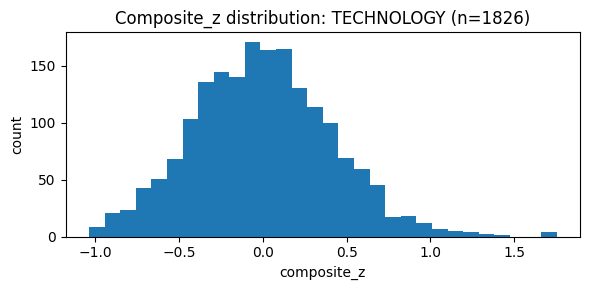

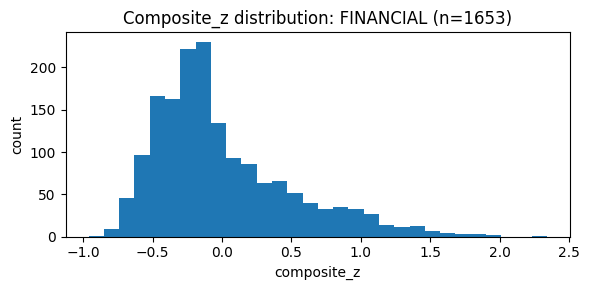

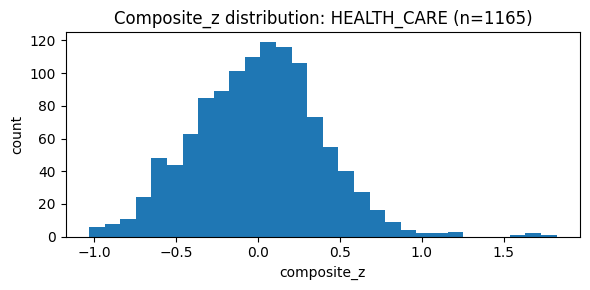

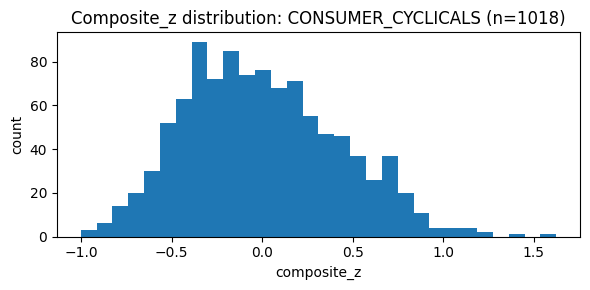

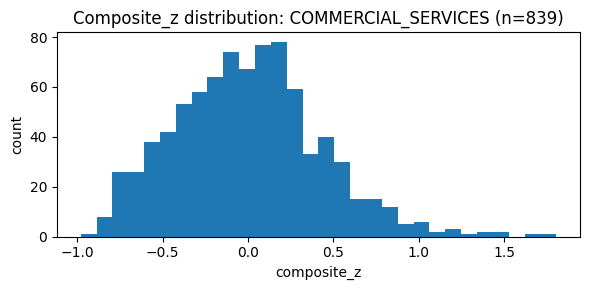

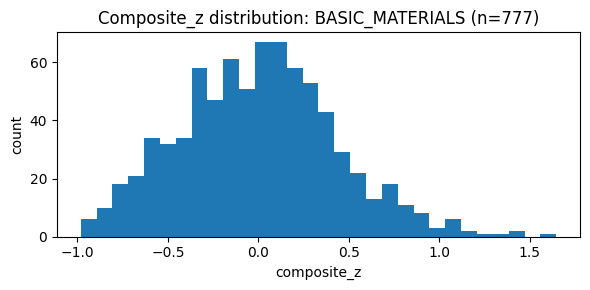

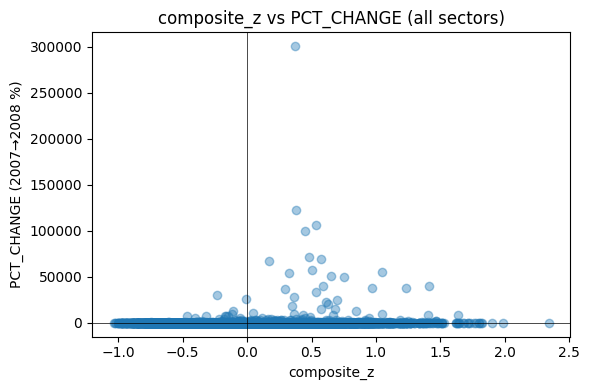

In [ ]:
# Step 9: simple plots (matplotlib only)
import matplotlib.pyplot as plt
import numpy as np

# Histogram of composite_z for each sector (top sectors)
with engine.connect() as conn:
    df_all = pd.read_sql(text("SELECT * FROM vw_sector_composite_risk"), conn)

sectors = df_all['SECTOR'].value_counts().index.tolist()[:6]  # top 6 sectors
for s in sectors:
    arr = df_all[df_all['SECTOR'] == s]['composite_z'].dropna().values
    if len(arr) < 5:
        continue
    plt.figure(figsize=(6,3))
    plt.hist(arr, bins=30)
    plt.title(f'Composite_z distribution: {s} (n={len(arr)})')
    plt.xlabel('composite_z')
    plt.ylabel('count')
    plt.tight_layout()
    plt.show()

# Scatter composite_z vs PCT_CHANGE (for common companies)
with engine.connect() as conn:
    df_merge = pd.read_sql(text("""
        SELECT v.BARRID, v.SECTOR, v.composite_z, p.PCT_CHANGE
        FROM vw_sector_composite_risk v
        JOIN pct_changes p ON v.BARRID = p.BARRID
        WHERE v.composite_z IS NOT NULL AND p.PCT_CHANGE IS NOT NULL
    """), conn)

plt.figure(figsize=(6,4))
plt.scatter(df_merge['composite_z'], df_merge['PCT_CHANGE'], alpha=0.4)
plt.xlabel('composite_z')
plt.ylabel('PCT_CHANGE (2007→2008 %)')
plt.title('composite_z vs PCT_CHANGE (all sectors)')
plt.axvline(0, color='k', linewidth=0.5)
plt.axhline(0, color='k', linewidth=0.5)
plt.tight_layout()
plt.show()

CTE (WITH)

Readability: stepwise, easy to explain in presentation.

Performance (SQLite): Good. SQLite generally inlines CTEs (no forced materialization) so performance ≈ subquery in many cases. Use during development & demo.

Use when: you want clarity and to show intermediate steps in the video.

VIEW

Readability: Good for reuse, hides complexity behind name.

Performance (SQLite): Comparable to CTE (views are text macros and will be inlined). Great for final notebook to avoid copy/paste.

Use when: you need to reuse the logic across multiple queries / plotting cells.

SUBQUERY

Readability: Lower for complex logic; code dense.

Performance: Often similar or slightly better if optimizer can optimize aggressively. For SQLite, difference is usually small.

Use when: you want a single SQL statement or micro-optimize a specific query.

Recommendation

CTE version to walk through the logic, then create the VIEW and run the production queries against the VIEW for repeated visuals

# 6. JOIN Operations Showcase (20%)  - Talha
Demonstrate these JOIN types with meaningful analysis:

INNER JOIN: Companies surviving both years

LEFT JOIN: All 2007 companies, showing which disappeared

Simulated FULL OUTER JOIN: Complete picture using UNION approach

Show proper NULL handling in JOIN results

In [ ]:
from sqlalchemy import text
import pandas as pd

# Open a single connection block
with engine.connect() as conn:

    # ==========================================
    # 1) INNER JOIN: Companies surviving both years
    # NULL Handling: NULLIF(d07.PRICE, 0) prevents DivisionByZero errors.
    # ==========================================
    inner_sql = """
    SELECT
      d07.BARRID,
      d07.TICKER AS TICKER_2007,
      d08.TICKER AS TICKER_2008,
      d07.PRICE AS PRICE_2007,
      d08.PRICE AS PRICE_2008,
      ROUND((d08.PRICE - d07.PRICE) / NULLIF(d07.PRICE, 0) * 100.0, 4) AS PCT_CHANGE_07_08
    FROM "2007_data" d07
    INNER JOIN "2008_data" d08
      ON d07.BARRID = d08.BARRID;
    """
    df_inner = pd.read_sql(text(inner_sql), conn)

    print("=== 1. INNER JOIN (Surviving Both Years) ===")
    print(f"Shape: {df_inner.shape}")
    display(df_inner.head())
    print("\n" + "-"*50 + "\n")

    # ==========================================
    # 2) LEFT JOIN: All 2007 companies, showing which disappeared
    # NULL Handling: d08.BARRID IS NULL identifies vanished companies.
    # COALESCE ensures missing 2008 prices show as 0 instead of NaN.
    # ==========================================
    left_sql = """
    SELECT
      d07.BARRID AS BARRID_2007,
      d07.TICKER AS TICKER_2007,
      d08.BARRID AS BARRID_2008,
      COALESCE(d08.PRICE, 0) AS SAFE_PRICE_2008,
      CASE
        WHEN d08.BARRID IS NULL THEN 'Disappeared'
        ELSE 'Survived'
      END AS SURVIVAL_STATUS
    FROM "2007_data" d07
    LEFT JOIN "2008_data" d08
      ON d07.BARRID = d08.BARRID;
    """
    df_left = pd.read_sql(text(left_sql), conn)

    print("=== 2A. LEFT JOIN (All 2007 Universe & Disappearances) ===")
    print(f"Shape: {df_left.shape}")
    display(df_left.head())
    print("\n")

    # Filter to create a DataFrame with ONLY disappeared companies
    df_disappeared = df_left[df_left['SURVIVAL_STATUS'] == 'Disappeared'].copy()

    print("=== 2B. LEFT JOIN SUBSET (Only Disappeared Companies) ===")
    print(f"Shape: {df_disappeared.shape}")
    display(df_disappeared.head())
    print("\n" + "-"*50 + "\n")

    # ==========================================
    # 3) Simulated FULL OUTER JOIN: Complete picture using UNION
    # NULL Handling: COALESCE combines tickers so the final column
    # never has a missing ticker, regardless of which year it came from.
    # ==========================================
    full_outer_sql = """
    SELECT
      d07.BARRID AS BARRID_07,
      d08.BARRID AS BARRID_08,
      COALESCE(d07.TICKER, d08.TICKER) AS MASTER_TICKER,
      'Present in 07' AS SOURCE_07,
      CASE WHEN d08.BARRID IS NOT NULL THEN 'Present in 08' ELSE 'Missing in 08' END AS SOURCE_08
    FROM "2007_data" d07
    LEFT JOIN "2008_data" d08 ON d07.BARRID = d08.BARRID

    UNION

    SELECT
      d07.BARRID AS BARRID_07,
      d08.BARRID AS BARRID_08,
      COALESCE(d07.TICKER, d08.TICKER) AS MASTER_TICKER,
      CASE WHEN d07.BARRID IS NOT NULL THEN 'Present in 07' ELSE 'Missing in 07' END AS SOURCE_07,
      'Present in 08' AS SOURCE_08
    FROM "2008_data" d08
    LEFT JOIN "2007_data" d07 ON d08.BARRID = d07.BARRID;
    """
    df_outer = pd.read_sql(text(full_outer_sql), conn)

    print("=== 3. FULL OUTER JOIN (Total Complete Picture) ===")
    print(f"Shape: {df_outer.shape}")
    display(df_outer.head())

# 7. Database Documentation (Requirement)

## Entity Relationship Diagram (ERD) & Schema Design

**Diagram:** [View the Entity Relationship Diagram (ERD)](https://mermaid.ai/d/<redacted-course-data-file>)

### Tables
1.  **`2007_data` & `2008_data`**
    * **Primary Key:** `BARRID` (String)
    * **Composite Index:** `(INDNAME1, CAPITALIZATION)` for efficient sector-based filtering.
    * **Columns:** 49 columns including risk factors (`HBTA`, `SRISK_PERCENT`), identifiers, and descriptors.
2.  **`ind_to_sectors`**
    * **Purpose:** Normalization table mapping Industry names (`INDNAME`) to broader Sectors (`SECTOR`).
    * **Usage:** Joined with main data tables for sector-level aggregation.

### Data Cleaning & Naming Conventions
* **Column Renaming:** Original columns containing `%` (e.g., `SRISK%`) were renamed to `_PERCENT` (e.g., `SRISK_PERCENT`) to avoid SQL syntax errors.
* **Whitespace:** Leading/trailing whitespace removed from all string columns (e.g., `'FINSVCS '` → `'FINSVCS'`).
* **NULL Handling:**
    * Barra's `-999` placeholder values were converted to SQL `NULL` or `NaN` in Python before loading.
    * JOIN operations explicitly handle NULLs (e.g., using `COALESCE` or `IS NULL` checks).

### Estimation Universe
* **Filter Logic:** Analyses are restricted to the 2007 investible universe where `E3ESTU = 1` OR `NONESTU = 0` to avoid bias from non-investible assets.

In [ ]:
# RE-RUNNING RISK PREDICTION MODEL WITH ESTIMATION UNIVERSE FILTER
# Requirement: Use stocks in the 2007 estimation universe: E3ESTU = 1 or NONESTU = 0

import statsmodels.api as sm

# 1. Filter the 2007 dataframe for investible stocks
mask_investible = (df_2007['E3ESTU'] == 1) | (df_2007['NONESTU'] == 0)
df_investible = df_2007[mask_investible].copy()

print(f"Total Universe: {len(df_2007)}")
print(f"Investible Universe (E3ESTU=1 or NONESTU=0): {len(df_investible)}")

# 2. Prepare Data for Regression
risk_factors = ['TRADEACT', 'VOLTILTY', 'MOMENTUM', 'VALUE', 'EARNVAR', 'LEVERAGE']

# Merge with price data to get targets
df_reg_filtered = df_investible[['BARRID'] + risk_factors].merge(
    df_prices[['BARRID', 'PCT_CHANGE']],
    on='BARRID'
).dropna()

# 3. Run OLS on Filtered Data
X_filtered = df_reg_filtered[risk_factors]
y_filtered = df_reg_filtered['PCT_CHANGE']
X_filtered = sm.add_constant(X_filtered)

model_filtered = sm.OLS(y_filtered, X_filtered).fit()

print("\n--- OLS Regression Results (Investible Universe Only) ---")
print(model_filtered.summary())

# 8. Bonus: Early Warning System

**Objective:** Develop an early warning system based on the findings.

We will use the **Composite Risk Score** calculated in the Complex Query section (View: `vw_sector_composite_risk`) to flag companies with a score > 2.0 (2 standard deviations above sector mean). We then check how many of these "Red Flag" companies actually crashed (lost > 50% value) in 2008.

In [ ]:
# --- BONUS: SQL Cross-Validation Framework ---
cv_sql = """
WITH FoldAssignments AS (
    -- Randomly assign every company to one of 5 folds for Cross-Validation
    SELECT
        v.BARRID,
        v.composite_z,
        p.PCT_CHANGE,
        NTILE(5) OVER (ORDER BY RANDOM()) AS cv_fold
    FROM vw_sector_composite_risk v
    JOIN pct_changes p ON v.BARRID = p.BARRID
)
-- Test the Early Warning System's precision across each fold independently
SELECT
    cv_fold,
    COUNT(*) AS Flagged_Count,
    SUM(CASE WHEN PCT_CHANGE < -50 THEN 1 ELSE 0 END) AS Crashed_Count,
    ROUND((SUM(CASE WHEN PCT_CHANGE < -50 THEN 1.0 ELSE 0.0 END) / NULLIF(COUNT(*), 0)) * 100.0, 2) AS Precision_Pct
FROM FoldAssignments
WHERE composite_z > 1.5  -- Test threshold
GROUP BY cv_fold
ORDER BY cv_fold;
"""

with engine.connect() as conn:
    print("=== BONUS: 5-Fold Cross Validation of Early Warning System ===")
    df_cv = pd.read_sql(text(cv_sql), conn)
    display(df_cv)

# --- BONUS: Interactive Risk Dashboard (Talha)


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# Create interactive sliders and dropdowns
threshold_slider = widgets.FloatSlider(value=1.5, min=0.0, max=4.0, step=0.1, description='Z-Score:')
sector_dropdown = widgets.Dropdown(
    options=['All'] + list(pd.read_sql(text("SELECT DISTINCT SECTOR FROM vw_sector_composite_risk WHERE SECTOR IS NOT NULL;"), engine)['SECTOR']),
    value='All',
    description='Sector:'
)
output_table = widgets.Output()

def update_dashboard(change):
    with output_table:
        clear_output(wait=True)
        t_val = threshold_slider.value
        s_val = sector_dropdown.value

        # Parameterized query based on widget inputs
        sector_filter = f"AND v.SECTOR = '{s_val}'" if s_val != 'All' else ""

        dash_sql = f"""
            SELECT v.NAME, v.TICKER, v.SECTOR, v.composite_z, p.PCT_CHANGE
            FROM vw_sector_composite_risk v
            JOIN pct_changes p ON v.BARRID = p.BARRID
            WHERE v.composite_z > {t_val} {sector_filter}
            ORDER BY v.composite_z DESC
            LIMIT 10;
        """
        with engine.connect() as conn:
            dash_df = pd.read_sql(text(dash_sql), conn)
            print(f"Showing High-Risk Companies (Z > {t_val}) for Sector: {s_val}")
            display(dash_df)

# Link widgets to function and display
threshold_slider.observe(update_dashboard, names='value')
sector_dropdown.observe(update_dashboard, names='value')

print("=== BONUS: Interactive Risk Dashboard ===")
display(widgets.HBox([threshold_slider, sector_dropdown]))
display(output_table)

# Trigger initial load
update_dashboard(None)

## Data Handbook
* https://www.alacra.com/alacra/help/barra_handbook_US.pdf